# 02 · Limpieza e ingeniería de variables

Construye el pipeline reproducible de `src/data.py` y `src/features.py`: reglas de calidad, variables temporales/geográficas y codificación de zonas.

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
OUT = PROJECT_ROOT / "outputs"; FIG = PROJECT_ROOT / "reports" / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
TRAIN_MONTHS = ("2026-01", "2026-02"); VAL_MONTHS = ("2026-03",)
from src.data import load_clean_months, load_month, download_yellow_taxi_months, MODEL_COLUMNS
from src.features import add_duration, valid_duration_mask, add_basic_features, ZoneTargetEncoder, build_feature_matrix, NUMERIC_BASE

## 1. Reglas de limpieza y filas descartadas
Se conservan viajes con duración entre 1 y 180 min (misma regla del baseline), recogida dentro del mes esperado y zonas no nulas. Solo se leen las 6 columnas necesarias (`MODEL_COLUMNS`), lo que excluye de entrada todas las variables con leakage.

In [2]:
paths = download_yellow_taxi_months(TRAIN_MONTHS + VAL_MONTHS, PROJECT_ROOT / "data")
rows = []
for m, p in paths.items():
    raw = add_duration(load_month(p, columns=MODEL_COLUMNS))
    clean = load_clean_months((m,), PROJECT_ROOT / "data")
    rows.append({"month": m, "raw": len(raw), "clean": len(clean),
                 "dur_lt_1": int((raw.duration_min < 1).sum()),
                 "dur_gt_180": int((raw.duration_min > 180).sum()),
                 "wrong_month": int((raw.tpep_pickup_datetime.dt.strftime("%Y-%m") != m).sum()),
                 "passenger_nan": int(raw.passenger_count.isna().sum())})
    del raw, clean
quality = pd.DataFrame(rows); quality["dropped_pct"] = (1 - quality.clean / quality.raw) * 100
quality

,month,raw,clean,dur_lt_1,dur_gt_180,wrong_month,passenger_nan,dropped_pct
0,2026-01,3724889,3639382,83747,1755,7,1088058,2.295558
1,2026-02,3399866,3324718,73605,1528,16,1023317,2.210322
2,2026-03,3952451,3862063,89190,1181,19,945748,2.286885


In [3]:
train = load_clean_months(TRAIN_MONTHS, PROJECT_ROOT / "data")
val = load_clean_months(VAL_MONTHS, PROJECT_ROOT / "data")
print(f"train={len(train):,}  val={len(val):,}")
train.describe(include="all").T[["count","mean","min","max"]]

train=6,964,100  val=3,862,063


,count,mean,min,max
VendorID,6964100.0,1.814092,1.0,6.0
tpep_pickup_datetime,6964100,2026-01-30 18:17:36.431322,2026-01-01 00:00:00,2026-02-28 23:59:59
tpep_dropoff_datetime,6964100,2026-01-30 18:35:07.604784,2026-01-01 00:03:39,2026-03-01 01:20:14
passenger_count,4858558.0,1.241905,0.0,8.0
PULocationID,6964100.0,161.231957,1.0,265.0
DOLocationID,6964100.0,160.82863,1.0,265.0
duration_min,6964100.0,17.519558,1.0,179.966667


## 2. Valores faltantes
`passenger_count` es la única variable con nulos relevantes (~29 % en enero). No se descartan filas: se crea el indicador `passenger_missing` y se imputa con 1. Así el modelo puede aprender si "faltante" correlaciona con la duración (en la muestra, los viajes con dato faltante tienen mediana 16.2 min frente a 12.8 min).

In [4]:
feat = add_basic_features(train.sample(500_000, random_state=RANDOM_STATE))
print(feat.groupby("passenger_missing").duration_min.agg(["count","median","mean"]))
print(feat.groupby("vendor_id").duration_min.agg(["count","median"]))

                    count     median       mean
passenger_missing                              
0                  348759  12.750000  17.221178
1                  151241  16.233333  18.129855
            count     median
vendor_id                   
1           95360  14.816667
2          403923  13.733333
6             717  34.016667


## 3. Variables temporales
Hora, día de semana, fin de semana y codificación cíclica (seno/coseno). `pickup_month` se calcula pero **se excluye del modelo**: en validación temporal el mes de validación nunca aparece en train y un coeficiente lineal sobre el mes solo extrapolaría (al quitarlo, el MAE lineal bajó de 5.18 a 4.79 min en una prueba previa).

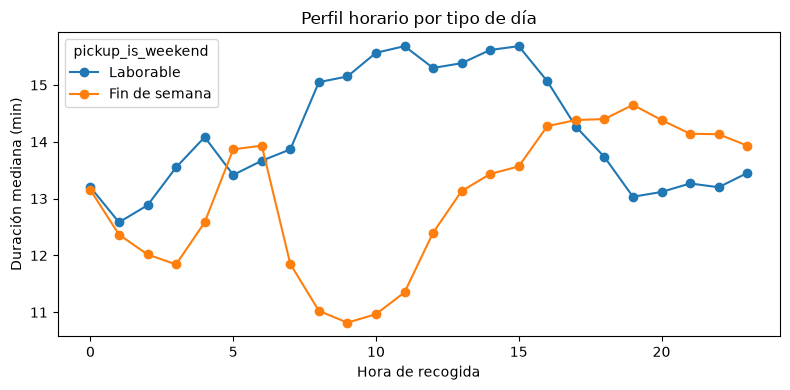

In [5]:
prof = feat.groupby(["pickup_is_weekend","pickup_hour"]).duration_min.median().unstack(0)
ax = prof.rename(columns={0:"Laborable",1:"Fin de semana"}).plot(marker="o", figsize=(8,4))
ax.set_xlabel("Hora de recogida"); ax.set_ylabel("Duración mediana (min)"); ax.set_title("Perfil horario por tipo de día")
plt.tight_layout(); plt.savefig(FIG/"07_profile_hour_weekend.png", dpi=150); plt.show()

## 4. Variables geográficas y codificación de zonas
262 zonas de recogida × destino no se pueden pasar como entero a un modelo lineal. `ZoneTargetEncoder` aprende en train la duración media (suavizada) por zona de recogida, de destino y por par. Suavizado con 20 pseudo-observaciones hacia el nivel padre (par → zonas → media global); zonas/pares no vistos reciben el nivel padre. `same_zone` marca viajes dentro de la misma zona.

**Nota de leakage:** el encoder usa `duration_min` de train, pero nunca de validación. Dentro de train el valor de cada viaje se incluye en su propia media (leve optimismo en pares raros); el suavizado lo mitiga y se mide en validación real.

In [6]:
enc = ZoneTargetEncoder(smoothing=20).fit(train, train.duration_min)
Xtr = build_feature_matrix(train, enc); Xva = build_feature_matrix(val, enc)
cov = val.set_index(["PULocationID","DOLocationID"]).index.isin(enc.pair_.index).mean()
print(f"Pares de validación vistos en train: {cov:.2%}")
print("NaN train/val:", int(Xtr.isna().sum().sum()), int(Xva.isna().sum().sum()))
print("Columnas:", list(Xtr.columns))
corr = pd.concat([Xva, val.duration_min], axis=1).corr()["duration_min"].drop("duration_min").sort_values()
corr

Pares de validación vistos en train: 99.90%
NaN train/val: 0 0
Columnas: ['pickup_hour', 'pickup_dayofweek', 'pickup_is_weekend', 'passenger_count', 'passenger_missing', 'vendor_id', 'same_zone', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'pu_zone_mean', 'do_zone_mean', 'pair_mean']


same_zone           -0.155557
hour_cos            -0.118505
vendor_id           -0.103311
pickup_is_weekend   -0.068299
pickup_dayofweek    -0.056845
pickup_hour         -0.028925
dow_cos             -0.009816
passenger_count      0.002650
passenger_missing    0.009109
hour_sin             0.022235
dow_sin              0.062494
do_zone_mean         0.451404
pu_zone_mean         0.504381
pair_mean            0.817470
Name: duration_min, dtype: float64

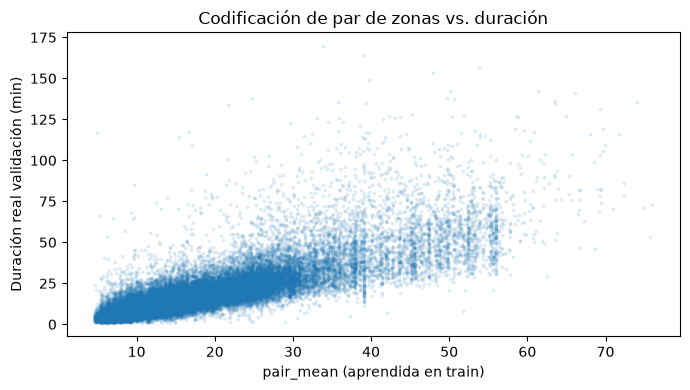

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(Xva["pair_mean"].sample(50_000, random_state=RANDOM_STATE), val.duration_min.loc[Xva["pair_mean"].sample(50_000, random_state=RANDOM_STATE).index], s=3, alpha=.1)
ax.set_xlabel("pair_mean (aprendida en train)"); ax.set_ylabel("Duración real validación (min)"); ax.set_title("Codificación de par de zonas vs. duración")
plt.tight_layout(); plt.savefig(FIG/"08_pair_mean_vs_duration.png", dpi=150); plt.show()

In [8]:
summary = {"train_rows": len(train), "val_rows": len(val), "features": list(Xtr.columns),
           "val_pair_coverage": float(cov), "quality": quality.to_dict("records")}
(OUT/"features_summary.json").write_text(json.dumps(summary, indent=2, default=int))

1095